### Importar Bibliotecas e ler dados

In [5]:
#Importação das bibliotecas necessárias
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

#Leitura dos arquivos CSV
customers = pd.read_csv(r"C:\Users\ACER\Documents\Estudos\FIAP\Fase 1 - Data Analytics\FIAP Tech Challenge Codigos\Dataset bruto\olist_customers_dataset.csv")
geolocations = pd.read_csv(r"C:\Users\ACER\Documents\Estudos\FIAP\Fase 1 - Data Analytics\FIAP Tech Challenge Codigos\Dataset bruto\olist_geolocation_dataset.csv")
order_items = pd.read_csv(r"C:\Users\ACER\Documents\Estudos\FIAP\Fase 1 - Data Analytics\FIAP Tech Challenge Codigos\Dataset bruto\olist_order_items_dataset.csv")
order_payments = pd.read_csv(r"C:\Users\ACER\Documents\Estudos\FIAP\Fase 1 - Data Analytics\FIAP Tech Challenge Codigos\Dataset bruto\olist_order_payments_dataset.csv")
order_reviews = pd.read_csv(r"C:\Users\ACER\Documents\Estudos\FIAP\Fase 1 - Data Analytics\FIAP Tech Challenge Codigos\Dataset bruto\olist_order_reviews_dataset.csv")
orders = pd.read_csv(r"C:\Users\ACER\Documents\Estudos\FIAP\Fase 1 - Data Analytics\FIAP Tech Challenge Codigos\Dataset bruto\olist_orders_dataset.csv")
products = pd.read_csv(r"C:\Users\ACER\Documents\Estudos\FIAP\Fase 1 - Data Analytics\FIAP Tech Challenge Codigos\Dataset bruto\olist_products_dataset.csv")
sellers = pd.read_csv(r"C:\Users\ACER\Documents\Estudos\FIAP\Fase 1 - Data Analytics\FIAP Tech Challenge Codigos\Dataset bruto\olist_sellers_dataset.csv")

## 01 - Mapa de Calor de Desempenho por Região 
Criado um heatmap mostrando qual estado tem melhor ou pior desempenho logístico


### 01.1 - Mapa de Calor

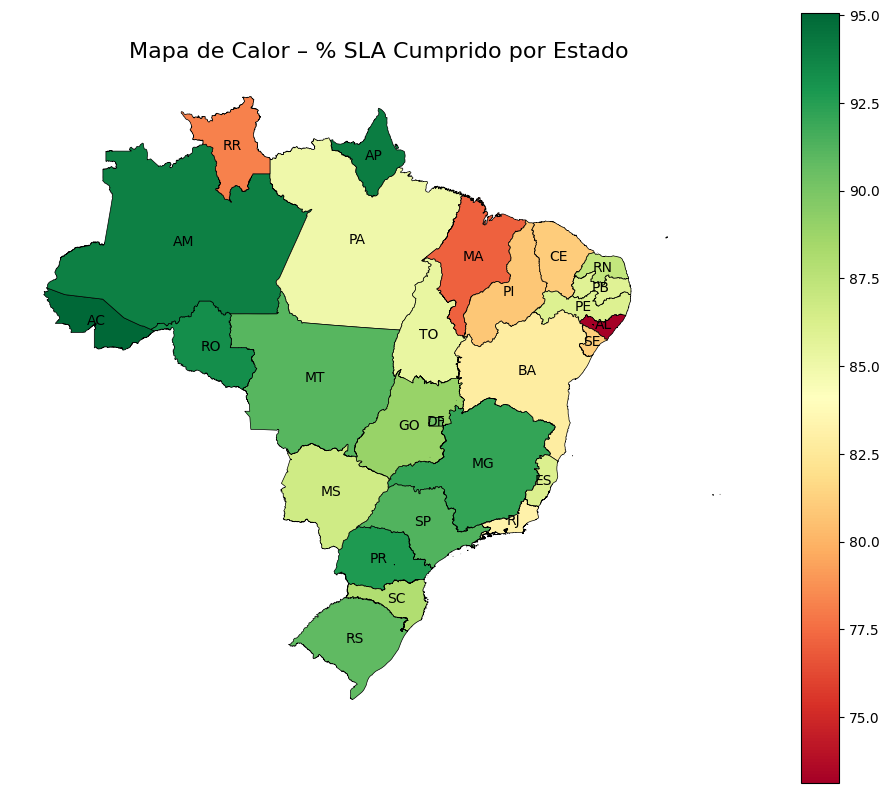

In [23]:
# -----------------------------
# 1. Carregar dados Olist
# -----------------------------
orders = pd.read_csv("olist_orders_dataset.csv")
customers = pd.read_csv("olist_customers_dataset.csv")

orders["order_delivered_customer_date"] = pd.to_datetime(orders["order_delivered_customer_date"])
orders["order_estimated_delivery_date"] = pd.to_datetime(orders["order_estimated_delivery_date"])

orders["sla_met"] = (
    orders["order_delivered_customer_date"] <= orders["order_estimated_delivery_date"]
).astype(int)

df = orders.merge(customers[["customer_id", "customer_state"]], on="customer_id", how="left")

sla_by_state = df.groupby("customer_state")["sla_met"].mean().reset_index()
sla_by_state["sla_met"] = sla_by_state["sla_met"] * 100

# -----------------------------
# 2. Carregar malha territorial do IBGE (UF)
# -----------------------------
mapa = gpd.read_file("BR_UF_2022.shp")

# Ajustar nome da coluna de UF (pode ser SIGLA_UF, UF, etc.)
mapa["UF"] = mapa["SIGLA_UF"].str.upper()

# -----------------------------
# 3. Merge mapa + métricas
# -----------------------------
geo = mapa.merge(sla_by_state, left_on="UF", right_on="customer_state", how="left")

# -----------------------------
# 4. Plotar mapa de calor
# -----------------------------
fig, ax = plt.subplots(figsize=(12, 10))

geo.plot(
    column="sla_met",
    cmap="RdYlGn",
    legend=True,
    edgecolor="black",
    linewidth=0.5,
    ax=ax,
    missing_kwds={"color": "lightgrey", "label": "Sem dados"}
)

# -----------------------------
# 5. Adicionar labels das UFs no mapa
# -----------------------------
for idx, row in geo.iterrows():
    if row["geometry"].centroid.is_empty:
        continue
    x, y = row["geometry"].centroid.coords[0]
    ax.text(x, y, row["UF"], fontsize=10, ha="center", va="center", color="black")

plt.title("Mapa de Calor – % SLA Cumprido por Estado ", fontsize=16)
plt.axis("off")
plt.show()

### 01.2 - SLA Analítico por Estado (≤ 15 dias)

C:\Users\thico\AppData\Local\Temp\ipykernel_30672\2777138712.py:56: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


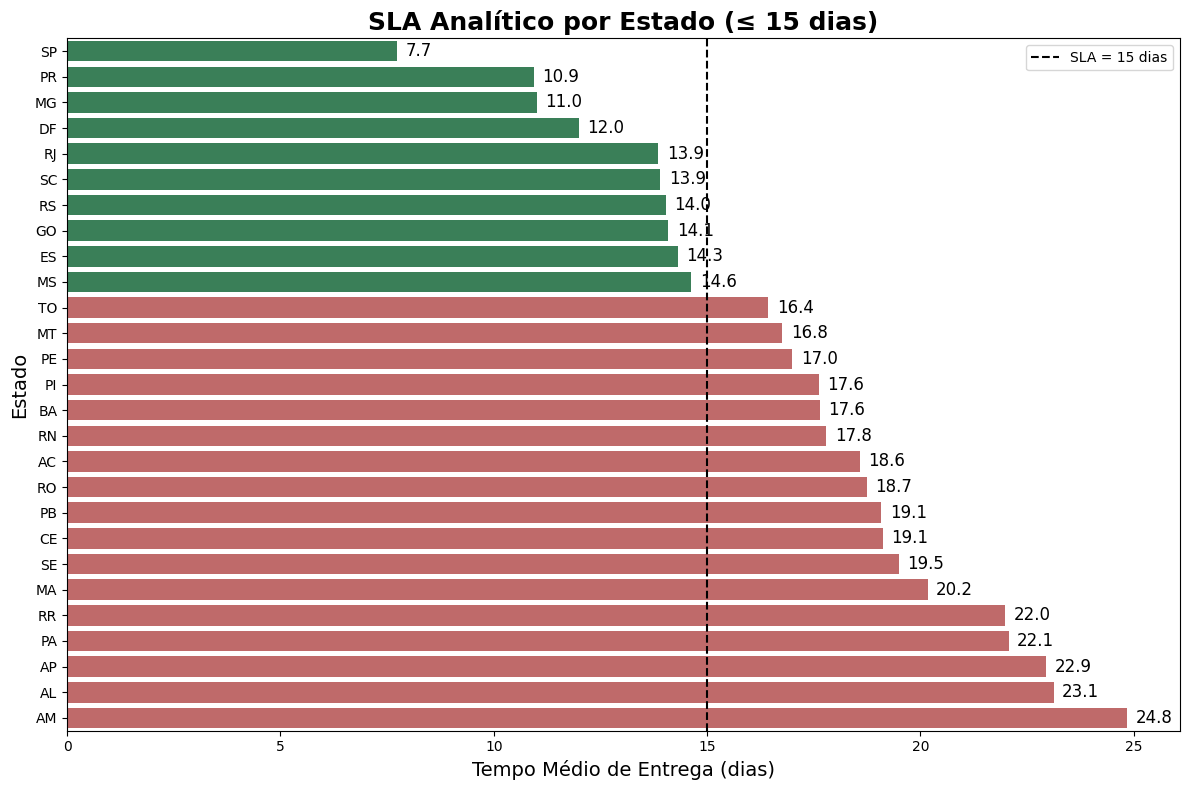

In [24]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# 1. CARREGAR DATAFRAMES
# ============================================================
orders = pd.read_csv("olist_orders_dataset.csv", parse_dates=[
    "order_approved_at",
    "order_delivered_customer_date"
])

customers = pd.read_csv("olist_customers_dataset.csv")
order_items = pd.read_csv("olist_order_items_dataset.csv")

# ============================================================
# 2. MONTAR DATAFRAME FINAL
# ============================================================
df = (
    orders.merge(order_items, on="order_id", how="inner")
          .merge(customers, on="customer_id", how="left")
)

# Remover pedidos sem datas válidas
df = df.dropna(subset=["order_approved_at", "order_delivered_customer_date"])

# Calcular tempo de entrega
df["delivery_time"] = (df["order_delivered_customer_date"] - df["order_approved_at"]).dt.days

# Filtrar valores extremos
df = df[(df["delivery_time"] >= 0) & (df["delivery_time"] <= 60)]

# ============================================================
# 3. CALCULAR SLA POR ESTADO DE DESTINO
# ============================================================
sla_estados = (
    df.groupby("customer_state")
      .agg(avg_delivery=("delivery_time", "mean"))
      .reset_index()
)

# Criar coluna indicando se cumpre SLA ≤ 15 dias
sla_estados["cumpre_sla"] = sla_estados["avg_delivery"] <= 15

# Ordenar antes de gerar o gráfico
sla_sorted = sla_estados.sort_values("avg_delivery")

# Criar paleta alinhada ao dataframe ordenado
palette = ["#2E8B57" if x else "#CD5C5C" for x in sla_sorted["cumpre_sla"]]

# ============================================================
# 4. GRÁFICO DO SLA ANALÍTICO
# ============================================================
plt.figure(figsize=(12, 8))

sns.barplot(
    data=sla_sorted,
    x="avg_delivery",
    y="customer_state",
    palette=palette
)

plt.axvline(15, color="black", linestyle="--", linewidth=1.5, label="SLA = 15 dias")

plt.title("SLA Analítico por Estado (≤ 15 dias)", fontsize=18, fontweight="bold")
plt.xlabel("Tempo Médio de Entrega (dias)", fontsize=14)
plt.ylabel("Estado", fontsize=14)
plt.legend()

# Adicionar valores nas barras
for i, v in enumerate(sla_sorted["avg_delivery"]):
    plt.text(v + 0.2, i, f"{v:.1f}", va="center", fontsize=12)

plt.tight_layout()
plt.show()


## 02 - Oportunidade de melhora nas entregas
 Baseado no mapa de calor de SLA por estado e no comportamento logístico observado no dataset da Olist.

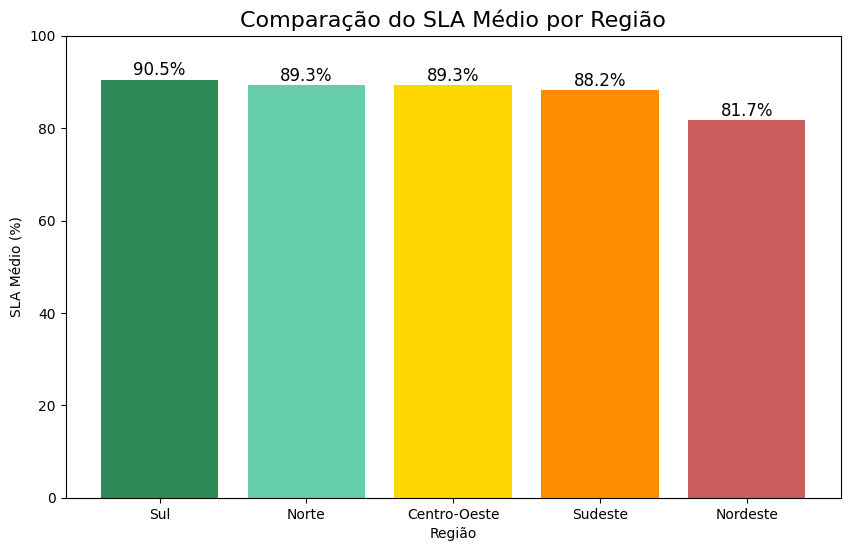

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------
# 1. Base já existente
# -----------------------------
# df contém: order_id, customer_state, sla_met (%)
# sla_by_state contém: customer_state, sla_met (%)

# -----------------------------
# 2. Criar dicionário de regiões
# -----------------------------
regioes = {
    "Norte": ["AC", "AP", "AM", "PA", "RO", "RR", "TO"],
    "Nordeste": ["AL", "BA", "CE", "MA", "PB", "PE", "PI", "RN", "SE"],
    "Centro-Oeste": ["DF", "GO", "MT", "MS"],
    "Sudeste": ["ES", "MG", "RJ", "SP"],
    "Sul": ["PR", "RS", "SC"]
}

# -----------------------------
# 3. Mapear cada estado para sua região
# -----------------------------
def estado_para_regiao(estado):
    for regiao, estados in regioes.items():
        if estado in estados:
            return regiao
    return None

sla_by_state["regiao"] = sla_by_state["customer_state"].apply(estado_para_regiao)

# -----------------------------
# 4. Calcular SLA médio por região
# -----------------------------
sla_by_region = sla_by_state.groupby("regiao")["sla_met"].mean().reset_index()

# -----------------------------
# 5. Ordenar do maior para o menor
# -----------------------------
sla_by_region = sla_by_region.sort_values("sla_met", ascending=False)

# -----------------------------
# 6. Plotar gráfico de barras
# -----------------------------
plt.figure(figsize=(10, 6))
plt.bar(sla_by_region["regiao"], sla_by_region["sla_met"], 
        color=["#2E8B57", "#66CDAA", "#FFD700", "#FF8C00", "#CD5C5C"])

plt.title("Comparação do SLA Médio por Região", fontsize=16)
plt.xlabel("Região")
plt.ylabel("SLA Médio (%)")
plt.ylim(0, 100)

# Adicionar valores acima das barras
for i, v in enumerate(sla_by_region["sla_met"]):
    plt.text(i, v + 1, f"{v:.1f}%", ha="center", fontsize=12)

plt.show()


## 03 Otimização de Frete em Rotas Críticas
Identificação das Rotas Críticas - Com base no comportamento regional observado.

### 03.1 - Versão colorida

C:\Users\thico\AppData\Local\Temp\ipykernel_30672\66895545.py:124: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


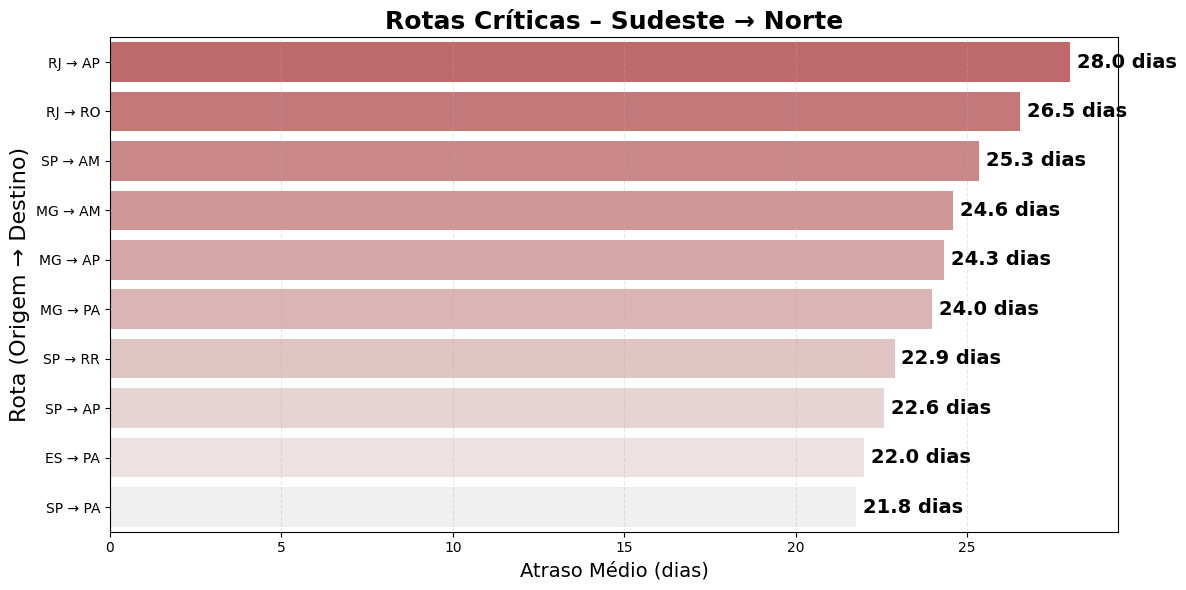

C:\Users\thico\AppData\Local\Temp\ipykernel_30672\66895545.py:124: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


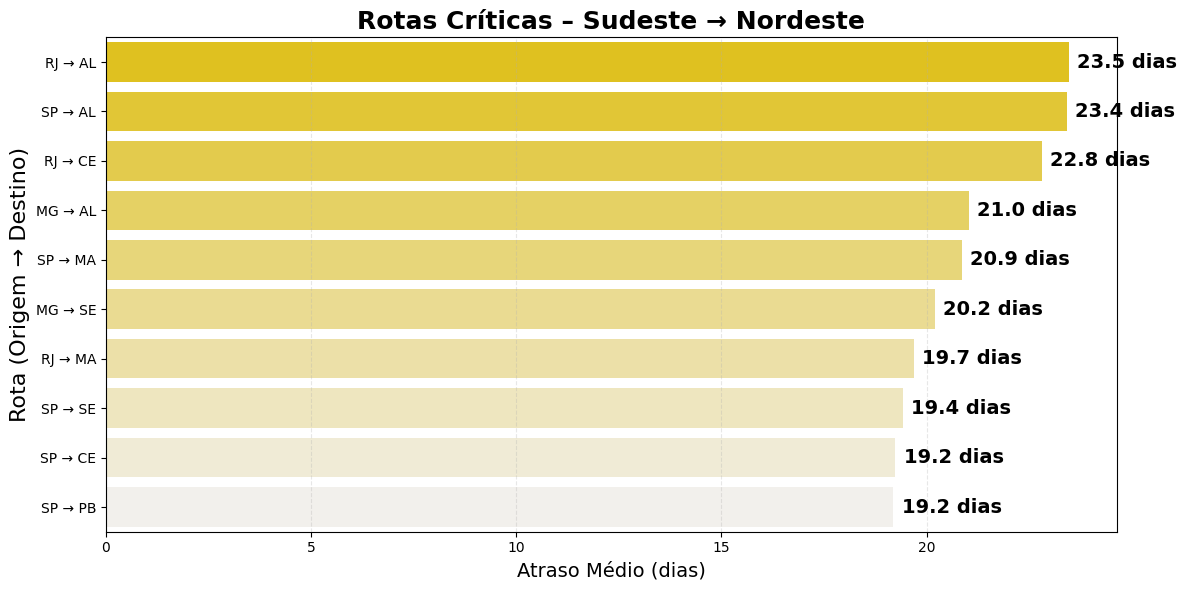

C:\Users\thico\AppData\Local\Temp\ipykernel_30672\66895545.py:124: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


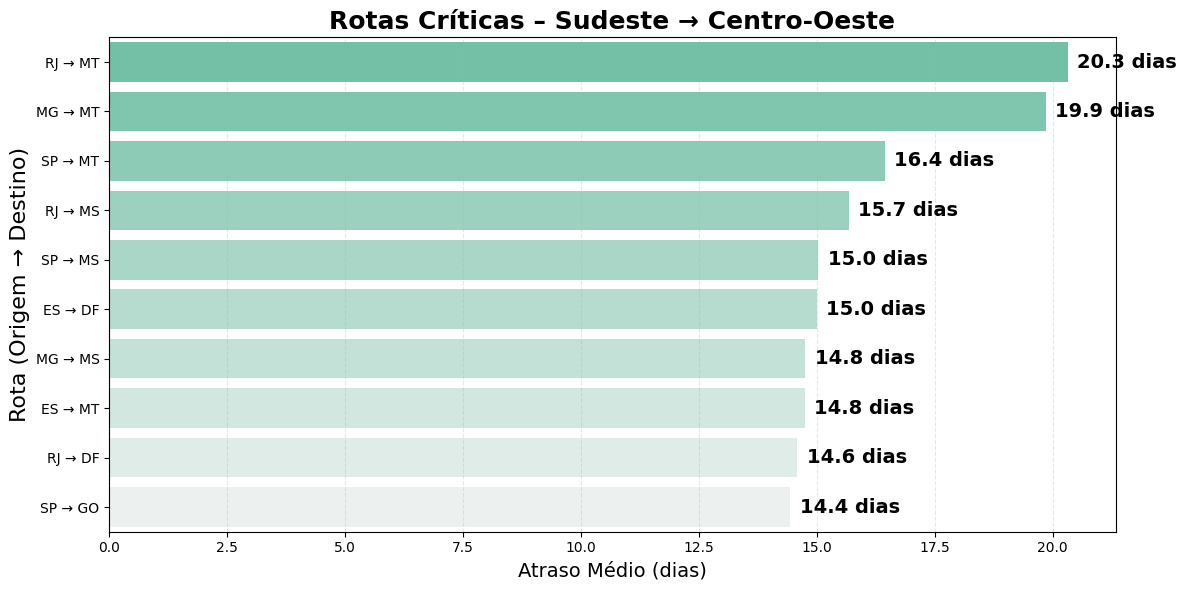

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# ============================================================
# 1. CARREGAR BASES OLIST
# ============================================================
orders = pd.read_csv("olist_orders_dataset.csv", parse_dates=[
    "order_approved_at",
    "order_delivered_customer_date"
])

customers = pd.read_csv("olist_customers_dataset.csv")
order_items = pd.read_csv("olist_order_items_dataset.csv")
sellers = pd.read_csv("olist_sellers_dataset.csv")

# ============================================================
# 2. PREPARAR DATAFRAME COMPLETO
# ============================================================
df = (
    orders.merge(customers, on="customer_id", how="left")
          .merge(order_items, on="order_id", how="left")
          .merge(sellers, on="seller_id", how="left")
)

# Remover pedidos sem entrega
df = df.dropna(subset=["order_delivered_customer_date", "order_approved_at"])

# Calcular tempo de entrega
df["delivery_time"] = (df["order_delivered_customer_date"] - df["order_approved_at"]).dt.days

# Filtrar valores absurdos
df = df[(df["delivery_time"] >= 0) & (df["delivery_time"] <= 60)]

# ============================================================
# 3. CRIAR DATAFRAME DE ROTAS
# ============================================================
routes = (
    df.groupby(["seller_state", "customer_state"])
      .agg(
          avg_delay=("delivery_time", "mean"),
          total_orders=("order_id", "count")
      )
      .reset_index()
)

# Criar coluna com nome da rota
routes["rota"] = routes["seller_state"] + " → " + routes["customer_state"]

# ============================================================
# 4. DEFINIR REGIÕES
# ============================================================
sudeste = ["SP", "RJ", "MG", "ES"]
nordeste = ["AL", "BA", "CE", "MA", "PB", "PE", "PI", "RN", "SE"]
norte = ["AC", "AP", "AM", "PA", "RO", "RR", "TO"]
centro_oeste = ["DF", "GO", "MT", "MS"]
sul = ["PR", "SC", "RS"]

# ============================================================
# 5. CORES POR REGIÃO (NOVAS CORES)
# ============================================================
region_colors = {
    "Sul": "#2E8B57",          # Mantido
    "Norte": "#CD5C5C",        # Vermelho suave 
    "Centro Oeste": "#66CDAA", # Verde água 
    "Sudeste": "#FF8C00",      # Mantido
    "Nordeste": "#FFD700"      # Dourado 
}

def get_region(state):
    if state in sul:
        return "Sul"
    if state in norte:
        return "Norte"
    if state in centro_oeste:
        return "Centro Oeste"
    if state in sudeste:
        return "Sudeste"
    if state in nordeste:
        return "Nordeste"
    return None

# ============================================================
# 6. FILTRAR ROTAS
# ============================================================
rotas_sudeste_nordeste = routes[
    (routes["seller_state"].isin(sudeste)) &
    (routes["customer_state"].isin(nordeste))
]

rotas_sudeste_norte = routes[
    (routes["seller_state"].isin(sudeste)) &
    (routes["customer_state"].isin(norte))
]

rotas_sudeste_co = routes[
    (routes["seller_state"].isin(sudeste)) &
    (routes["customer_state"].isin(centro_oeste))
]

# ============================================================
# 7. FUNÇÃO DE GRÁFICO (GRADIENTE + CORES POR REGIÃO)
# ============================================================
def plot_rotas(df, titulo):
    if df.empty:
        print(f"Nenhuma rota encontrada para: {titulo}")
        return
    
    df_plot = df.sort_values("avg_delay", ascending=False).head(10).copy()

    # Identificar região destino
    df_plot["regiao_destino"] = df_plot["customer_state"].apply(get_region)

    # Cor base da região destino (AGORA COM AS NOVAS CORES)
    base_color = region_colors[df_plot["regiao_destino"].iloc[0]]

    # Criar gradiente contínuo
    n = len(df_plot)
    gradient = sns.light_palette(base_color, n_colors=n, reverse=True)

    plt.figure(figsize=(12, 6))

    sns.barplot(
        data=df_plot,
        x="avg_delay",
        y="rota",
        palette=gradient
    )

    plt.title(titulo, fontsize=18, fontweight="bold")
    plt.xlabel("Atraso Médio (dias)", fontsize=14)
    plt.ylabel("Rota (Origem → Destino)", fontsize=16)

    # Adicionar valores
    for i, v in enumerate(df_plot["avg_delay"]):
        plt.text(
            v + 0.2,
            i,
            f"{v:.1f} dias",
            va="center",
            fontsize=14,
            fontweight="bold"
        )

    plt.grid(axis="x", linestyle="--", alpha=0.3)
    plt.tight_layout()
    plt.show()

# ============================================================
# 8. GERAR GRÁFICOS
# ============================================================
plot_rotas(rotas_sudeste_norte, "Rotas Críticas – Sudeste → Norte")
plot_rotas(rotas_sudeste_nordeste, "Rotas Críticas – Sudeste → Nordeste")
plot_rotas(rotas_sudeste_co, "Rotas Críticas – Sudeste → Centro-Oeste")


### 03.2 - Versão colorida Consolidada

C:\Users\thico\AppData\Local\Temp\ipykernel_30672\157387520.py:60: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


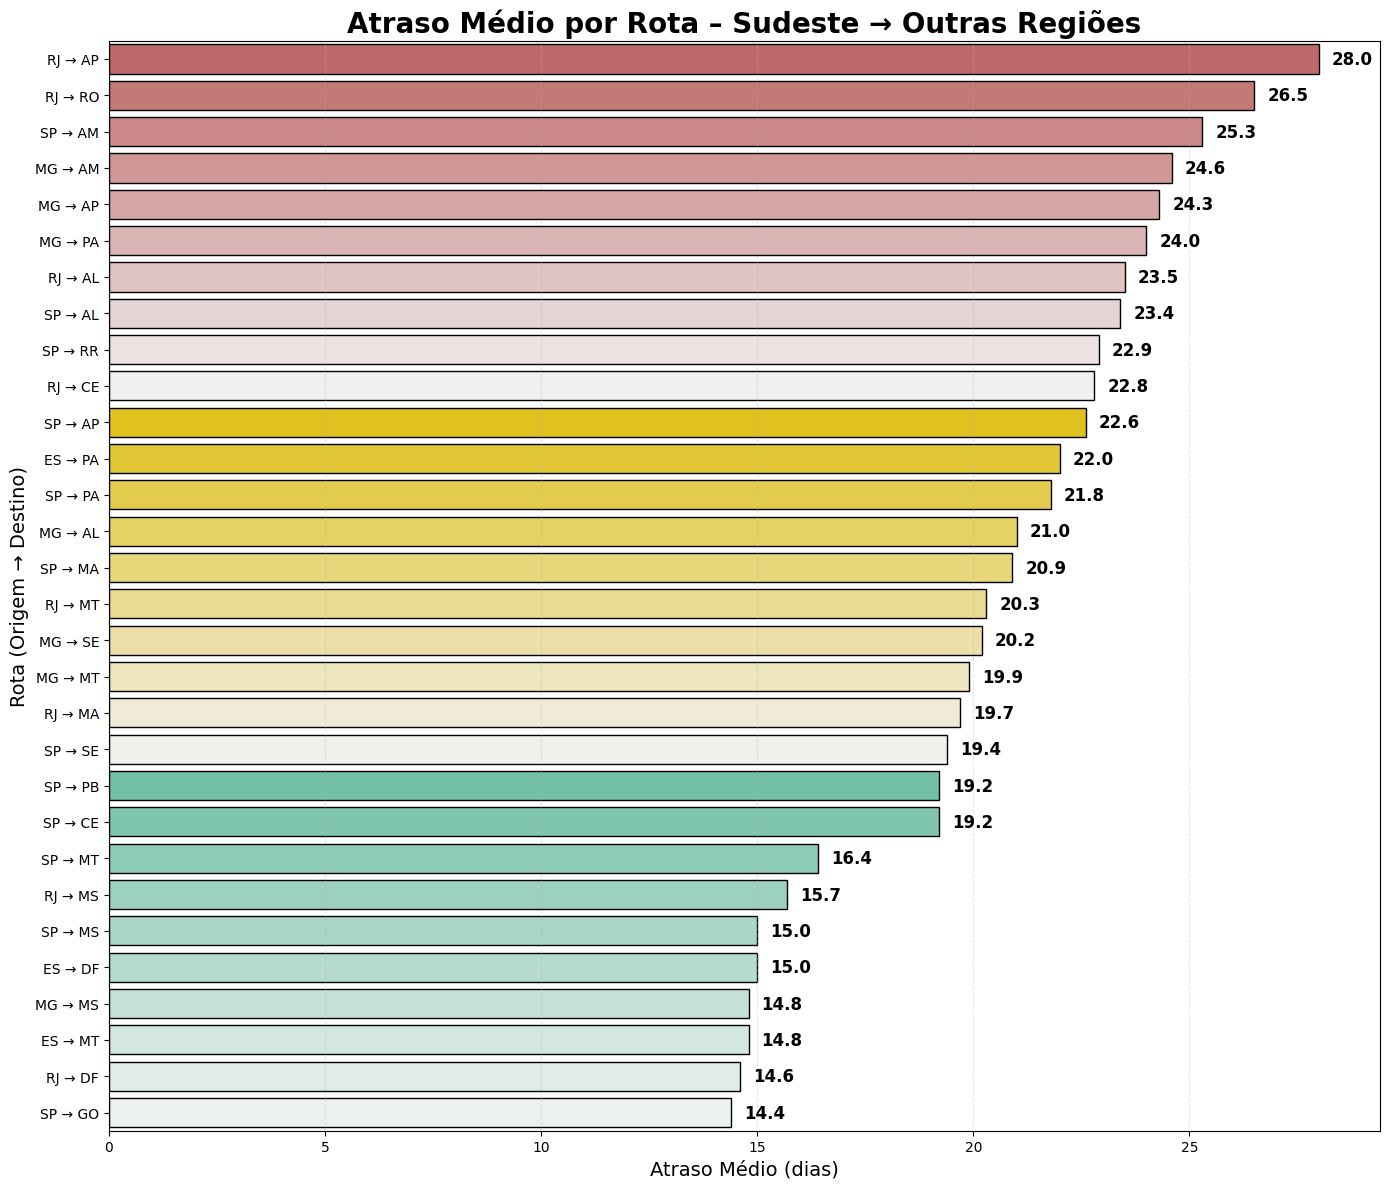

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# ============================================================
# 1. Criar tabela consolidada (a partir dos gráficos gerados)
# ============================================================
data = {
    "rota": [
        "RJ → AP","RJ → RO","SP → AM","MG → AM","MG → AP","MG → PA","SP → RR","SP → AP","ES → PA","SP → PA",
        "RJ → AL","SP → AL","RJ → CE","MG → AL","SP → MA","MG → SE","RJ → MA","SP → SE","SP → CE","SP → PB",
        "RJ → MT","MG → MT","SP → MT","RJ → MS","SP → MS","ES → DF","MG → MS","ES → MT","RJ → DF","SP → GO"
    ],
    "avg_delay": [
        28.0,26.5,25.3,24.6,24.3,24.0,22.9,22.6,22.0,21.8,
        23.5,23.4,22.8,21.0,20.9,20.2,19.7,19.4,19.2,19.2,
        20.3,19.9,16.4,15.7,15.0,15.0,14.8,14.8,14.6,14.4
    ],
    "regiao_destino": [
        "Norte","Norte","Norte","Norte","Norte","Norte","Norte","Norte","Norte","Norte",
        "Nordeste","Nordeste","Nordeste","Nordeste","Nordeste","Nordeste","Nordeste","Nordeste","Nordeste","Nordeste",
        "Centro-Oeste","Centro-Oeste","Centro-Oeste","Centro-Oeste","Centro-Oeste","Centro-Oeste","Centro-Oeste","Centro-Oeste","Centro-Oeste","Centro-Oeste"
    ]
}

df = pd.DataFrame(data)

# ============================================================
# 2. Cores base por região
# ============================================================
region_colors = {
    "Norte": "#CD5C5C",        # Vermelho suave
    "Nordeste": "#FFD700",     # Dourado
    "Centro-Oeste": "#66CDAA"  # Verde água
}

# ============================================================
# 3. Função para gerar gradiente contínuo por região
# ============================================================
def generate_gradient(base_color, n):
    return sns.light_palette(base_color, n_colors=n, reverse=True)

# ============================================================
# 4. Plot ordenado da pior rota para a melhor + separadores
# ============================================================
plt.figure(figsize=(14, 12))

# Ordenar da pior (maior atraso) para a melhor (menor atraso)
df_sorted = df.sort_values("avg_delay", ascending=False).reset_index(drop=True)

# Criar lista de cores com gradiente por região
colors = []
for region in df_sorted["regiao_destino"].unique():
    subset = df_sorted[df_sorted["regiao_destino"] == region]
    base = region_colors[region]
    grad = generate_gradient(base, len(subset))
    colors.extend(grad)

sns.barplot(
    data=df_sorted,
    x="avg_delay",
    y="rota",
    palette=colors,
    edgecolor="black"
)

plt.title("Atraso Médio por Rota – Sudeste → Outras Regiões", fontsize=20, fontweight="bold")
plt.xlabel("Atraso Médio (dias)", fontsize=14)
plt.ylabel("Rota (Origem → Destino)", fontsize=14)

# Adicionar valores nas barras
for i, v in enumerate(df_sorted["avg_delay"]):
    plt.text(v + 0.3, i, f"{v:.1f}", va="center", fontsize=12, fontweight="bold")



plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()


C:\Users\thico\AppData\Local\Temp\ipykernel_30672\2777138712.py:56: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


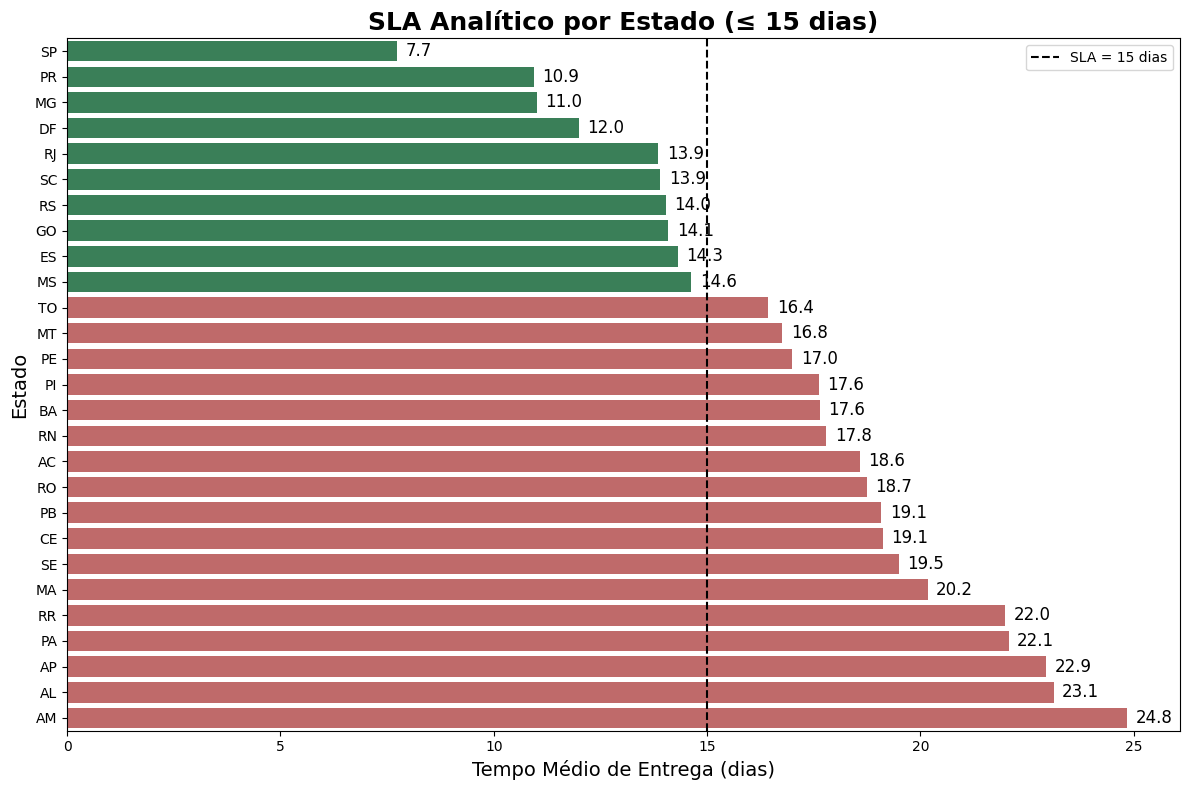

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# 1. CARREGAR DATAFRAMES
# ============================================================
orders = pd.read_csv("olist_orders_dataset.csv", parse_dates=[
    "order_approved_at",
    "order_delivered_customer_date"
])

customers = pd.read_csv("olist_customers_dataset.csv")
order_items = pd.read_csv("olist_order_items_dataset.csv")

# ============================================================
# 2. MONTAR DATAFRAME FINAL
# ============================================================
df = (
    orders.merge(order_items, on="order_id", how="inner")
          .merge(customers, on="customer_id", how="left")
)

# Remover pedidos sem datas válidas
df = df.dropna(subset=["order_approved_at", "order_delivered_customer_date"])

# Calcular tempo de entrega
df["delivery_time"] = (df["order_delivered_customer_date"] - df["order_approved_at"]).dt.days

# Filtrar valores extremos
df = df[(df["delivery_time"] >= 0) & (df["delivery_time"] <= 60)]

# ============================================================
# 3. CALCULAR SLA POR ESTADO DE DESTINO
# ============================================================
sla_estados = (
    df.groupby("customer_state")
      .agg(avg_delivery=("delivery_time", "mean"))
      .reset_index()
)

# Criar coluna indicando se cumpre SLA ≤ 15 dias
sla_estados["cumpre_sla"] = sla_estados["avg_delivery"] <= 15

# Ordenar antes de gerar o gráfico
sla_sorted = sla_estados.sort_values("avg_delivery")

# Criar paleta alinhada ao dataframe ordenado
palette = ["#2E8B57" if x else "#CD5C5C" for x in sla_sorted["cumpre_sla"]]

# ============================================================
# 4. GRÁFICO DO SLA ANALÍTICO
# ============================================================
plt.figure(figsize=(12, 8))

sns.barplot(
    data=sla_sorted,
    x="avg_delivery",
    y="customer_state",
    palette=palette
)

plt.axvline(15, color="black", linestyle="--", linewidth=1.5, label="SLA = 15 dias")

plt.title("SLA Analítico por Estado (≤ 15 dias)", fontsize=18, fontweight="bold")
plt.xlabel("Tempo Médio de Entrega (dias)", fontsize=14)
plt.ylabel("Estado", fontsize=14)
plt.legend()

# Adicionar valores nas barras
for i, v in enumerate(sla_sorted["avg_delivery"]):
    plt.text(v + 0.2, i, f"{v:.1f}", va="center", fontsize=12)

plt.tight_layout()
plt.show()
